# 02 · Detecção e contagem: resultados reais
Lê `experiments/*.json` (produzidos por `training/eval_predictions.py`). O limiar de confiança vem do val; o teste é uma **fazenda inédita**.

In [1]:
import sys, json; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({'figure.dpi': 110})
EX = '../experiments/'
L = lambda n: json.load(open(EX + n + '.json'))
full, es, coco = L('yolo11s_cattle_full'), L('yolo11s_cattle_es'), L('coco_yolo11s_zeroshot')
rows = []
for nm, e in (('COCO zero-shot', coco), ('YOLO11s parada antecipada', es), ('YOLO11s 40 épocas', full)):
    for sp in ('val', 'test'):
        x = e[sp]; rows.append({'modelo': nm, 'split': sp, 'conf': e['conf_operacional'], 'mAP50': round(x['map50'], 3), 'mAP50-95': round(x['map50_95'], 3), 'precisão': round(x['prf']['precision'], 3) if x['prf']['precision'] == x['prf']['precision'] else None, 'revocação': round(x['prf']['recall'], 3), 'MAE': round(x['contagem']['mae'], 2), 'viés': round(x['contagem']['bias'], 2), 'GT': int(x['contagem']['gt_total']), 'previsto': int(x['contagem']['pred_total'])})
pd.DataFrame(rows)

,modelo,split,conf,mAP50,mAP50-95,precisão,revocação,MAE,viés,GT,previsto
0,COCO zero-shot,val,0.05,0.000,0.000,NaN,0.000,8.71,-8.71,357,0
1,COCO zero-shot,test,0.05,0.030,0.010,0.587,0.033,8.29,-8.29,809,46
2,YOLO11s parada antecipada,val,0.30,0.542,0.113,0.584,0.630,2.68,0.68,357,385
3,YOLO11s parada antecipada,test,0.30,0.103,0.022,0.108,0.337,19.11,18.65,809,2525
4,YOLO11s 40 épocas,val,0.25,0.589,0.127,0.701,0.630,1.80,-0.88,357,321
5,YOLO11s 40 épocas,test,0.25,0.102,0.020,0.126,0.269,11.16,9.95,809,1724


## Previsto × verdade por imagem (modelo selecionado)
Se o modelo contasse certo, os pontos ficariam sobre a diagonal.

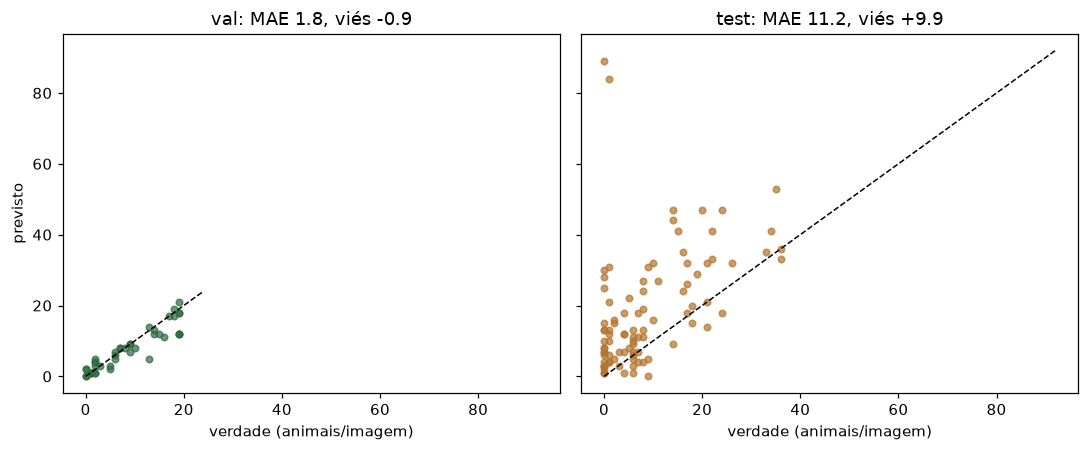

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True, sharey=True)
for a, sp, c in zip(ax, ('val', 'test'), ('#2f6b3f', '#b3752f')):
    im = full[sp]['imagens']; g = np.array([i['gt'] for i in im]); p = np.array([i['pred'] for i in im])
    a.scatter(g, p, s=18, alpha=.7, c=c); m = max(g.max(), p.max()) + 3; a.plot([0, m], [0, m], 'k--', lw=1); a.set_title(f'{sp}: MAE {np.abs(p-g).mean():.1f}, viés {np.mean(p-g):+.1f}'); a.set_xlabel('verdade (animais/imagem)')
ax[0].set_ylabel('previsto'); plt.tight_layout(); plt.show()

## Erro de contagem por voo (teste) com IC por bootstrap de voos

                 voo  altitude_m  imagens  GT  previsto   MAE  viés
DJI_202306231103_031         100       17  77       162  6.76  5.00
DJI_202306271323_032          60       23  94       202  6.17  4.70
DJI_202309151045_056         100       19 214       413 11.63 10.47
DJI_202309261339_058         100       18 209       486 15.39 15.39
DJI_202309261339_059         100       15 215       461 18.13 16.40

IC95 MAE por voo-bootstrap: [7.4, 15.5] | n_voos = 5


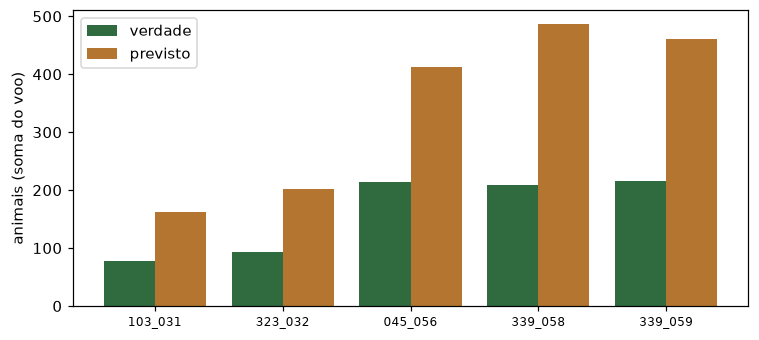

In [3]:
t = full['test']
FL = json.load(open('../data/raw/zenodo/download_plan.json'))['flights']
d = pd.DataFrame([{'voo': k, 'altitude_m': FL[k]['alt'], 'imagens': v['n'], 'GT': int(v['gt_total']), 'previsto': int(v['pred_total']), 'MAE': round(v['mae'], 2), 'viés': round(v['bias'], 2)} for k, v in t['por_voo'].items()])
print(d.to_string(index=False))
print('\nIC95 MAE por voo-bootstrap:', [round(x, 1) for x in t['contagem_ic95_bootstrap_por_voo']['mae']], '| n_voos =', t['contagem_ic95_bootstrap_por_voo']['n_unidades'])
fig, ax = plt.subplots(figsize=(7, 3.2)); x = np.arange(len(d)); ax.bar(x - .2, d.GT, .4, label='verdade', color='#2f6b3f'); ax.bar(x + .2, d.previsto, .4, label='previsto', color='#b3752f'); ax.set_xticks(x); ax.set_xticklabels([v[-7:] for v in d.voo], rotation=0, fontsize=8); ax.legend(); ax.set_ylabel('animais (soma do voo)'); plt.tight_layout(); plt.show()

## Imagens sem nenhum animal (teste): falsos positivos puros

In [4]:
z = t['por_densidade']['0']; print('imagens sem animais:', z['n'], '| animais previstos nelas:', int(z['pred_total']), '| média por imagem: %.1f' % (z['pred_total'] / z['n']))
im0 = [i for i in t['imagens'] if i['gt'] == 0]
print('por voo:', pd.Series([i['flight'][-7:] for i in im0 for _ in range(i['pred'])]).value_counts().to_dict())

imagens sem animais: 20 | animais previstos nelas: 276 | média por imagem: 13.8
por voo: {'339_059': 157, '045_056': 51, '339_058': 37, '103_031': 18, '323_032': 13}


## Escolha do limiar (val): F1 × confiança

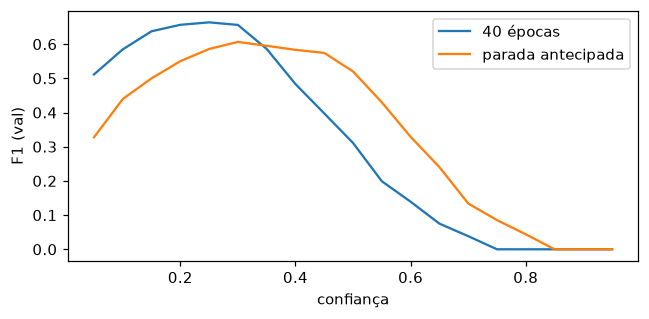

In [5]:
fig, ax = plt.subplots(figsize=(6, 3))
for nm, e in (('40 épocas', full), ('parada antecipada', es)):
    f = e['f1_val_por_conf']; ax.plot([float(k) for k in f], [v if v == v else 0 for v in f.values()], label=nm)
ax.set_xlabel('confiança'); ax.set_ylabel('F1 (val)'); ax.legend(); plt.tight_layout(); plt.show()

In [6]:
import os
if os.path.exists(EX + 'yolo11s_cattle_adapt__jalogny_holdout.json'):
    rows = []
    for nm, n in (('parada antecipada', 'yolo11s_cattle_es__jalogny_holdout'), ('40 épocas', 'yolo11s_cattle_full__jalogny_holdout'), ('40 épocas + adaptação', 'yolo11s_cattle_adapt__jalogny_holdout')):
        x = L(n)['test']; rows.append({'modelo': nm, 'imagens': x['n_images'], 'GT': int(x['contagem']['gt_total']), 'previsto': int(x['contagem']['pred_total']), 'mAP50': round(x['map50'], 3), 'precisão': round(x['prf']['precision'], 3), 'revocação': round(x['prf']['recall'], 3), 'MAE': round(x['contagem']['mae'], 2), 'viés': round(x['contagem']['bias'], 2)})
    display(pd.DataFrame(rows))
else:
    print('experimento de adaptação ainda não avaliado')

,modelo,imagens,GT,previsto,mAP50,precisão,revocação,MAE,viés
0,parada antecipada,57,523,1639,0.089,0.101,0.317,19.86,19.58
1,40 épocas,57,523,1076,0.084,0.117,0.241,11.14,9.70
2,40 épocas + adaptação,57,523,462,0.512,0.645,0.570,1.70,-1.07
